[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 0 — Complexité](theme0_complexite.ipynb) · [Thème 2 — Matrices](theme2_matrices_simulation.ipynb) ➡

# Thème 1 — Listes, sets et dictionnaires

**Dans ce notebook, tu vas apprendre :**
- comment fonctionnent une liste, un set et un dictionnaire ;
- pourquoi `x in un_set` est immédiat alors que `x in une_liste` parcourt tout (le hachage) ;
- choisir la bonne structure pour « déjà vu ? » et « combien de fois ? ».

**Prérequis :** thème 0 (notation O)

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Le problème de départ
> On te donne une liste de nombres. Renvoie le **premier nombre qui apparaît pour la deuxième fois** quand on lit de gauche à droite (ou `None` s'il n'y en a pas).
> Exemple : `[3, 1, 4, 1, 5]` → `1`.

Idée naturelle : lire les nombres un par un et, pour chacun, se demander « l'ai-je déjà vu ? ». Toute la difficulté est là : **comment se souvenir efficacement de ce qu'on a déjà vu ?**

Python propose trois « boîtes » pour ranger des données. Elles ne répondent pas toutes aussi vite à cette question.

## Le concept : trois structures, trois usages

### 1. La liste — une rangée de cases numérotées
`[3, 1, 4, 1, 5]` : chaque élément a une **position** (son indice) : 0, 1, 2, 3, 4.
- Lire `liste[2]` est immédiat — O(1) : on connaît la position, on y va directement.
- Mais `4 in liste` oblige Python à **regarder les cases une par une** jusqu'à trouver 4 — O(n).
- La liste garde l'**ordre** et accepte les **doublons**.

### 2. Le set (ensemble) — un vestiaire avec des casiers
Un set garde **une seule copie** de chaque valeur, et **n'a pas d'ordre**.

Sa force : `x in mon_set` est **immédiat** — O(1) en moyenne, même avec un million d'éléments. Comment est-ce possible ? Grâce au **hachage** :
- quand on ajoute une valeur, Python calcule à partir de cette valeur un numéro de casier (le **hash**) et la range dans ce casier ;
- quand on demande `x in mon_set`, Python recalcule le hash de `x` et va **directement** au bon casier. Il ne parcourt rien.

C'est le vestiaire de tout à l'heure : on ne fouille pas tous les manteaux, on va au crochet indiqué par le ticket.

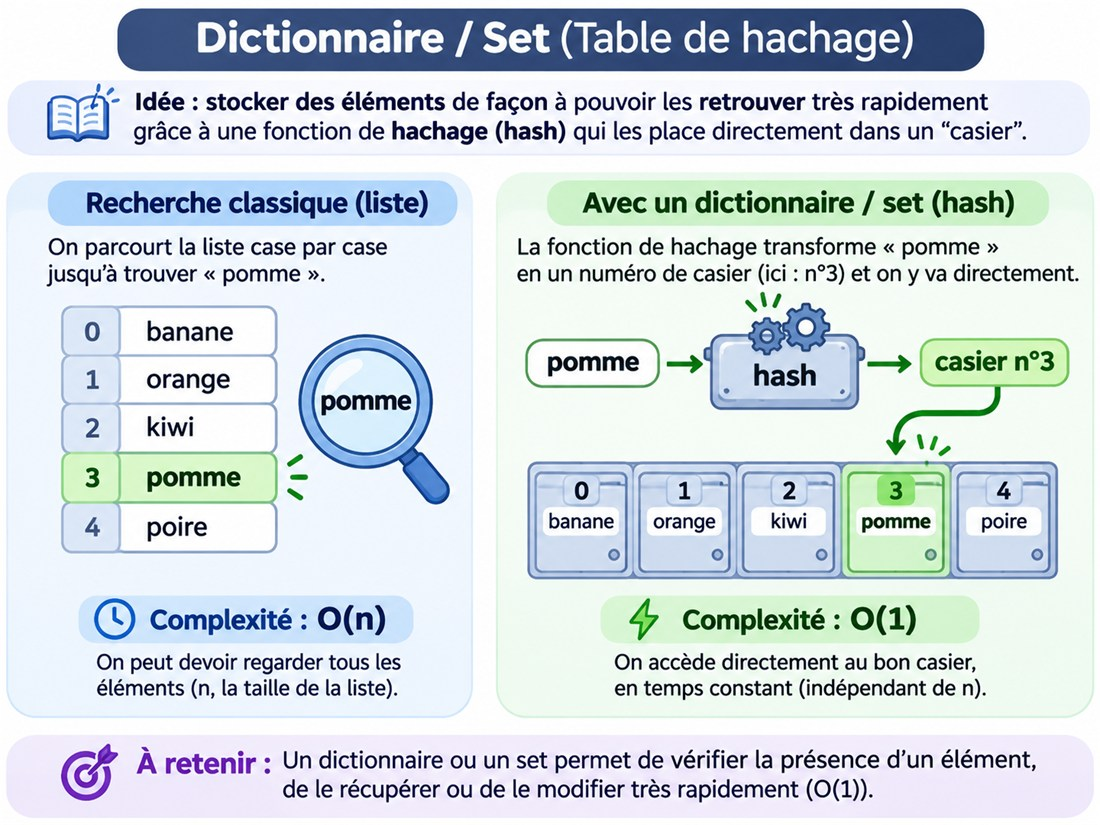

Sur l'image : pour trouver « pomme », la liste regarde les cases une par une (O(n)) ; le set calcule le hash de « pomme », obtient le casier n°3 et y va directement (O(1)). Le dict, présenté juste après, fonctionne de la même façon avec ses clés. (Les casiers sont dessinés dans le même ordre que la liste pour faciliter la comparaison ; en réalité, c'est le hash qui choisit le casier, et c'est pour ça qu'un set n'a pas d'ordre.)

Conséquence : un set ne peut contenir que des valeurs **qui ne peuvent pas être modifiées** (nombres, chaînes, tuples). Une liste peut changer après coup, son numéro de casier deviendrait faux : Python refuse (`TypeError: unhashable type: 'list'`).

### 3. Le dictionnaire — un vestiaire où chaque casier contient une information
Un dict associe une **clé** à une **valeur** : `{"pomme": 3, "poire": 1}`.
Il utilise le même hachage que le set, appliqué aux clés : `"pomme" in d` et `d["pomme"]` sont immédiats.

Usages typiques :
- **compter** : clé = l'élément, valeur = son nombre d'apparitions ;
- **mémoriser une information** : clé = l'élément, valeur = sa position, son prix, etc.

### Résumé
| Je veux… | Structure | Pourquoi |
|---|---|---|
| garder un ordre, accéder par position | `list` | indices 0, 1, 2… |
| savoir si j'ai **déjà vu** une valeur | `set` | `in` en O(1) |
| **compter**, ou **associer une info** à une valeur | `dict` | clé → valeur, accès en O(1) |

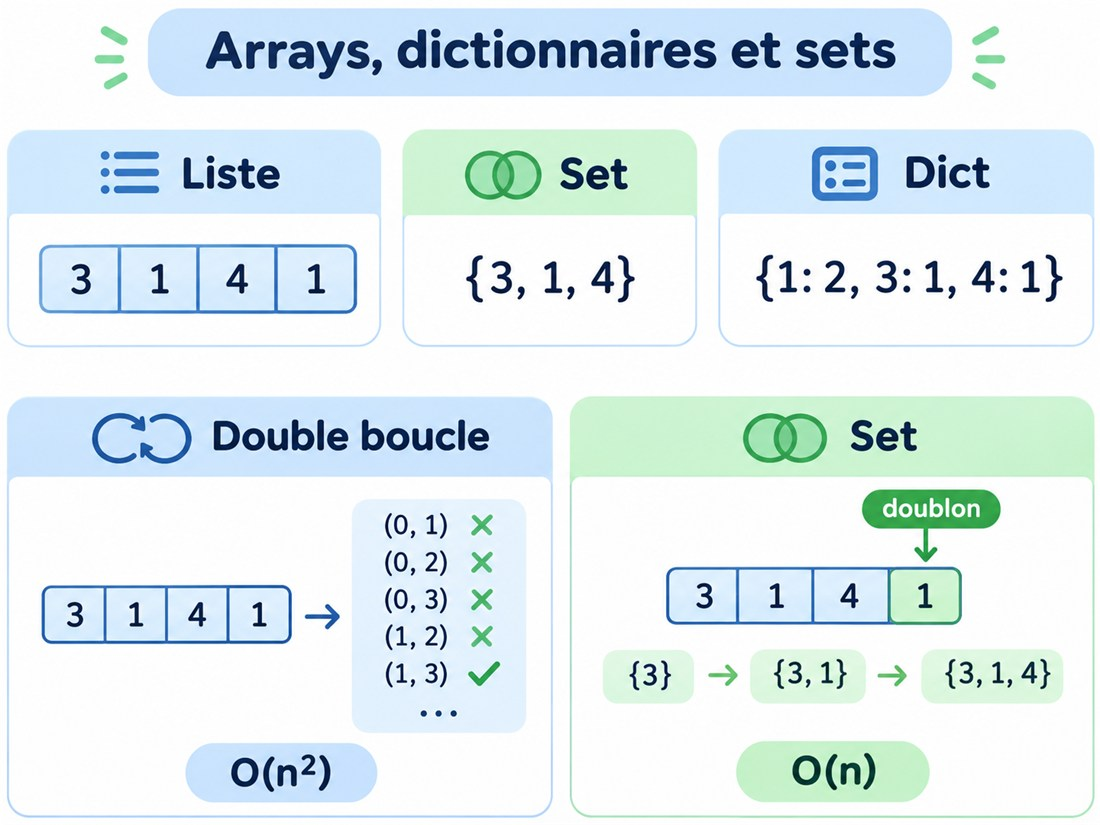

**Sur l'image**, avec les nombres `[3, 1, 4, 1]` :
- en haut, les trois structures : la **liste** garde tout, dans l'ordre et doublon compris ; le **set** ne garde qu'une copie de chaque valeur ; le **dict** compte les apparitions (`1` apparaît 2 fois) ;
- en bas, un aperçu de la suite : chercher le doublon en comparant **toutes les paires de positions** (double boucle, O(n²)), ou en lisant la liste **une seule fois** avec un set des nombres déjà vus (O(n)).

## On manipule

In [ ]:
vus = set()          # attention : {} crée un DICT vide, pas un set !
vus.add(3)
vus.add(1)
vus.add(3)           # 3 est déjà présent : rien ne change
print(vus)           # {1, 3} — un seul 3, et l'ordre n'est pas garanti
print(len(vus))      # 2
print(3 in vus)      # True
print(7 in vus)      # False

# Convertir une liste en set supprime les doublons
print(set([3, 1, 4, 1, 5, 9, 5]))

In [ ]:
compte = {}
for fruit in ["pomme", "poire", "pomme", "kiwi", "pomme"]:
    # compte.get(fruit, 0) : la valeur si la clé existe, sinon 0
    compte[fruit] = compte.get(fruit, 0) + 1

print(compte)                # {'pomme': 3, 'poire': 1, 'kiwi': 1}
print(compte["pomme"])       # 3
print("banane" in compte)    # False

for fruit, nombre in compte.items():     # parcourir les paires (clé, valeur)
    print(fruit, "apparaît", nombre, "fois")

In [ ]:
# Deux erreurs classiques : lis bien le message d'erreur à chaque fois.

compte = {}
try:
    compte["pomme"] += 1          # la clé "pomme" n'existe pas encore
except KeyError as e:
    print("KeyError :", e, "→ utiliser compte.get(cle, 0) + 1")

try:
    s = {[1, 2]}                  # une liste ne peut pas entrer dans un set
except TypeError as e:
    print("TypeError :", e, "→ utiliser un tuple : {(1, 2)}")

## Résoudre le problème de départ

### Version naïve : comparer chaque élément avec tous ceux d'avant

In [ ]:
def premier_doublon_naif(nombres):
    for j in range(len(nombres)):        # pour chaque position j…
        for i in range(j):               # …on regarde toutes les positions avant j
            if nombres[i] == nombres[j]:
                return nombres[j]
    return None

print(premier_doublon_naif([3, 1, 4, 1, 5]))   # 1

C'est correct, mais il y a deux boucles imbriquées → **O(n²)**. Avec 100 000 nombres, c'est environ 5 milliards de comparaisons.

### Version avec un set : un seul passage
On lit les nombres un par un et on **retient dans un set ceux qu'on a déjà vus**. Pour chaque nouveau nombre, une seule question : « est-il déjà dans le set ? » — et la réponse est immédiate.

**Trace à la main sur `[3, 1, 4, 1, 5]` :**

| Étape | `x` lu | `x in vus` ? | Action | `vus` après |
|---|---|---|---|---|
| 1 | 3 | non | on le retient | {3} |
| 2 | 1 | non | on le retient | {3, 1} |
| 3 | 4 | non | on le retient | {3, 1, 4} |
| 4 | 1 | **oui** | on renvoie 1 | — |

In [ ]:
def premier_doublon(nombres):
    vus = set()                # les nombres déjà rencontrés

    for x in nombres:          # un seul passage sur la liste : O(n)
        if x in vus:           # test immédiat grâce au set : O(1)
            return x           # c'est le premier nombre revu → réponse
        vus.add(x)             # sinon, on s'en souvient pour la suite

    return None                # tout lu sans revoir aucun nombre

tests = [
    [3, 1, 4, 1, 5],   # 1
    [1, 2, 3],         # aucun doublon → None
    [],                # liste vide → None (cas limite !)
    [5, 5],            # doublon immédiat → 5
    [2, 7, 7, 2],      # 7 est revu AVANT 2 → 7
]
for t in tests:
    print(t, "->", premier_doublon(t))

Deux remarques importantes :
- **Pourquoi pas `vus = []` ?** Le code marcherait aussi… mais `x in vus` sur une liste est une boucle cachée → on retombe en O(n²). Ici, **le choix de la structure est l'optimisation**.
- **Le dernier test `[2, 7, 7, 2]`** donne 7, pas 2. « Le premier nombre revu » (7, revu à la position 2) n'est pas la même chose que « le premier nombre qui a un doublon » (2). Lire l'énoncé **mot à mot** fait partie de l'exercice.

### Deuxième exemple : quand il faut compter → dict
> Renvoie le premier caractère d'un texte qui n'apparaît **qu'une seule fois**.
> `"abracadabra"` → `"c"` (a ×5, b ×2, r ×2, **c ×1**, d ×1).

Un set ne suffit plus : il sait dire « vu / pas vu », mais pas **combien de fois**. On fait **deux passages** :
1. on compte toutes les lettres dans un dict ;
2. on relit le texte **dans l'ordre** et on renvoie la première lettre dont le compte vaut 1.

Deux passages **l'un après l'autre** (pas imbriqués) : O(n) + O(n) = **O(n)**.

In [ ]:
def premier_caractere_unique(texte):
    compte = {}
    for c in texte:                        # passage 1 : compter
        compte[c] = compte.get(c, 0) + 1
    # pour "abracadabra" : {'a': 5, 'b': 2, 'r': 2, 'c': 1, 'd': 1}

    for c in texte:                        # passage 2 : relire dans l'ordre du texte
        if compte[c] == 1:
            return c
    return None

for mot in ["abracadabra", "aabb", "x", ""]:
    print(repr(mot), "->", premier_caractere_unique(mot))

# Bonus : Python sait compter tout seul
from collections import Counter
print(Counter("abracadabra"))

## Quand y penser ?
| Indice dans l'énoncé | Outil |
|---|---|
| « doublon », « apparaît deux fois », « déjà vu », « présent / absent » | **set** |
| « combien de fois », « fréquence », « le plus fréquent », « anagramme » | **dict** (compteur) |
| « retrouver la position de… », « associer X à Y » | **dict** |

## Les pièges
- `vus = {}` crée un **dict** vide, pas un set → écrire `set()`.
- `compte[x] += 1` sur une clé absente → `KeyError` → écrire `compte.get(x, 0) + 1`.
- Utiliser une liste pour « déjà vu » → O(n²) caché.
- Un set **n'a pas d'ordre** : si l'énoncé dit « premier », c'est la **boucle sur la liste** qui donne l'ordre, pas le set.
- Oublier les cas limites : liste vide, un seul élément, aucun doublon.

## À toi de jouer — paire de somme cible
> Écris `paire_somme(nombres, cible)` qui renvoie `True` s'il existe deux éléments **à des positions différentes** dont la somme vaut `cible`, sinon `False`.
> Exemple : `paire_somme([2, 7, 11, 15], 9)` → `True` (2 + 7).

- **Indice 1** : la version naïve teste toutes les paires (deux boucles → O(n²)). Peux-tu le faire en un seul passage ?
- **Indice 2** : quand tu lis `x`, quel nombre faudrait-il **avoir déjà vu** pour atteindre la cible ?

In [ ]:
def paire_somme(nombres, cible):
    # À toi de jouer !
    pass

verifier(paire_somme, [
    (([2, 7, 11, 15], 9), True),
    (([3, 3], 6), True),
    (([3], 6), False),          # un seul 3 : on ne peut pas l'utiliser deux fois
    (([1, 2, 4], 8), False),
    (([], 0), False),
    (([-1, 5, 3], 4), True),
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def paire_somme(nombres, cible):
    vus = set()
    for x in nombres:
        if cible - x in vus:   # le « complément » de x a-t-il déjà été vu ?
            return True
        vus.add(x)             # ajouté APRÈS le test : x ne peut pas faire une paire avec lui-même
    return False

# Un seul passage, chaque test en O(1) → O(n) au total.
```

</details>

---

**Suite :** [Thème 2 — Matrices (grilles) et simulation](theme2_matrices_simulation.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 1 — Listes, chaînes, dictionnaires et ensembles](exercices/serie1_listes_chaines_dicts_sets.ipynb) (6 exercices avec tests automatiques)